In [1]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

IMG_SIZE = (160, 160)
MODEL_DIR = Path("../models")
TEST_DIR = Path("../data/dogs_vs_cats_subset/test")

In [2]:
MODEL_PATH = MODEL_DIR / "mobilenetv2_cats_dogs.keras"

final_model = tf.keras.models.load_model(MODEL_PATH)

print("Final model loaded.")
final_model.summary()

Final model loaded.


Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │         1,281 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,261,829 (8.63 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 2,564 (10.02 KB)

In [3]:
test_paths = sorted(TEST_DIR.glob("*.jpg"))

def load_test_image(path):
    image = tf.io.read_file(path)
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.keras.applications.mobilenet_v2.preprocess_input(image)
    return image

test_ds = tf.data.Dataset.from_tensor_slices(
    [str(path) for path in test_paths]
)

test_ds = test_ds.map(
    load_test_image,
    num_parallel_calls=tf.data.AUTOTUNE
)

test_ds = test_ds.batch(32).prefetch(tf.data.AUTOTUNE)

print("Test images:", len(test_paths))

Test images: 100


In [4]:
probabilities = final_model.predict(test_ds, verbose=1).ravel()

predictions = (probabilities >= 0.5).astype(int)

print("Predictions generated:", len(predictions))

4/4 ━━━━━━━━━━━━━━━━━━━━ 2s 346ms/step
Predictions generated: 100


In [5]:
import pandas as pd

prediction_df = pd.DataFrame({
    "filename": [path.name for path in test_paths],
    "predicted_label": [
        "Dog" if pred == 1 else "Cat"
        for pred in predictions
    ],
    "dog_probability": probabilities
})

RESULTS_DIR = Path("../results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

prediction_df.to_csv(
    RESULTS_DIR / "test_predictions.csv",
    index=False
)

prediction_df.head(10)

,filename,predicted_label,dog_probability
0,1.jpg,Dog,0.999267
1,10.jpg,Cat,0.000950
2,100.jpg,Cat,0.008591
3,11.jpg,Cat,0.000065
4,12.jpg,Dog,0.971787
5,13.jpg,Cat,0.000428
6,14.jpg,Cat,0.010210
7,15.jpg,Cat,0.000172
8,16.jpg,Cat,0.001044
9,17.jpg,Dog,0.951909


In [6]:
def predict_image(image_path):
    image = tf.io.read_file(str(image_path))
    image = tf.image.decode_jpeg(image, channels=3)
    image = tf.image.resize(image, IMG_SIZE)

    image = tf.keras.applications.mobilenet_v2.preprocess_input(
        image
    )

    image_batch = tf.expand_dims(image, axis=0)

    dog_probability = float(
        final_model.predict(image_batch, verbose=0)[0][0]
    )

    predicted_class = "Dog" if dog_probability >= 0.5 else "Cat"
    confidence = (
        dog_probability
        if predicted_class == "Dog"
        else 1 - dog_probability
    )

    return predicted_class, confidence

In [7]:
for path in test_paths[:5]:
    predicted_class, confidence = predict_image(path)

    print(
        f"{path.name}: {predicted_class} "
        f"(confidence: {confidence:.2%})"
    )

1.jpg: Dog (confidence: 99.93%)
10.jpg: Cat (confidence: 99.91%)
100.jpg: Cat (confidence: 99.14%)
11.jpg: Cat (confidence: 99.99%)
12.jpg: Dog (confidence: 97.18%)


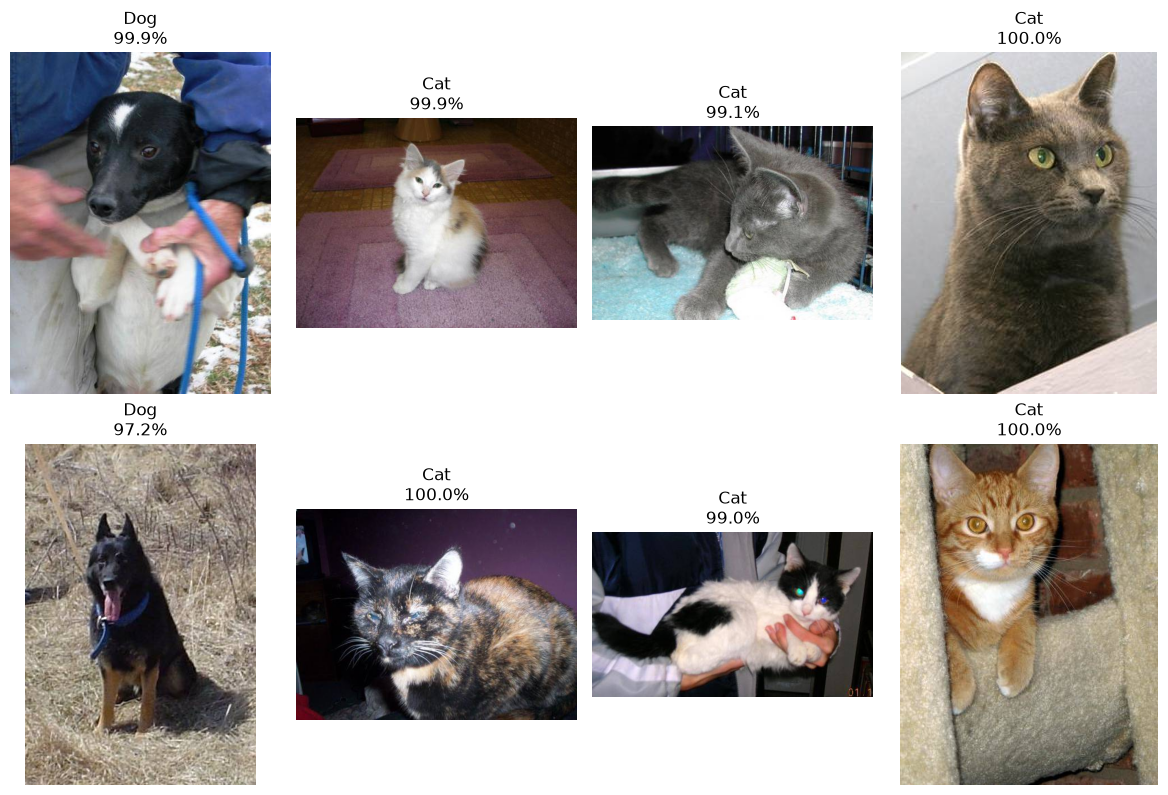

In [8]:
sample_paths = test_paths[:8]

plt.figure(figsize=(12, 8))

for i, path in enumerate(sample_paths):
    predicted_class, confidence = predict_image(path)

    image = Image.open(path).convert("RGB")

    plt.subplot(2, 4, i + 1)
    plt.imshow(image)
    plt.title(f"{predicted_class}\n{confidence:.1%}")
    plt.axis("off")

plt.tight_layout()
plt.show()